# PFAI Semester Project: Outlier Detection and Analysis (Member 1)

**Course:** Programming for AI (Instructor: Mahhek Tahir)
**Brief section:** 7. Outlier Detection and Analysis

### Objective
Detect potential outliers in the suitable numerical features using **two different methods**, compare the results, investigate whether the flagged observations are genuine values or data errors, and decide (with justification) whether they should be retained, removed or capped. Visualizations are used to compare the data before and after treatment.

### Plan
1. **Setup:** load `books_structured.csv` and rebuild the engineered length features
2. **Feature selection and validity check:** choose suitable features and check for impossible values
3. **Method 1:** IQR (Tukey fences, 1.5 × IQR)
4. **Method 2:** Z-score (|z| > 3)
5. **Comparison of the two methods**
6. **Investigation of the flagged observations**
7. **Treatment decision**
8. **Before and after visualizations**
9. **Leakage-free treatment for modelling** (fences learned from training data only)
10. **Summary**

All analysis is performed on the **original, unscaled values**.

## 1. Setup and loading the data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

INPUT_FILE = "books_structured.csv"   # typed dataset produced by 01_web_scraping.ipynb
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")

def save(fig, name):
    """Save a figure as PNG in figures/ so it can be reused in the report."""
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight", dpi=150)

df = pd.read_csv(INPUT_FILE)

# Engineered features (identical to the EDA)
df["desc_words"] = df["description"].str.split().str.len()   # books with no description stay missing (NaN), not 0
df["title_length"] = df["title"].str.len()

features = ["price", "stock", "desc_words", "title_length"]
print(df.shape)
df[features].describe().round(2)

(1000, 18)


,price,stock,desc_words,title_length
count,1000.00,1000.00,998.00,1000.00
mean,35.07,8.59,235.90,39.10
std,14.45,5.65,107.05,25.75
min,10.00,1.00,4.00,2.00
25%,22.11,3.00,176.25,19.00
50%,35.98,7.00,222.00,35.00
75%,47.46,14.00,278.00,53.00
max,59.99,22.00,1389.00,204.00


**What was done:** Imported the libraries, loaded `books_structured.csv` (produced by `01_web_scraping.ipynb`) and rebuilt the two engineered features used in the EDA: `desc_words` (number of words in the description) and `title_length` (number of characters in the title).

**Why:**
- The outlier analysis must use the same data and the same features as the EDA so that the results are consistent across sections.
- Books without a description keep `desc_words` as missing (`NaN`) rather than 0, so they are not mistaken for extremely short descriptions.
- The summary table gives the range of each feature before any detection method is applied.

**What the output shows / observations:**
- The dataset has 1000 rows. `desc_words` has a count of 998 because 2 books have no description.
- The table shows the minimum, quartiles and maximum of each feature, which are used to interpret the detection results below.

## 2. Choosing the features and checking for impossible values
The following numerical features are analysed: **price**, **stock**, **desc_words** and **title_length**.

Features that are **not** analysed:
- **rating:** a bounded ordinal scale (1 to 5). Every value is a legitimate rating, so outlier detection is not meaningful.
- **Constant and repeated columns** (`tax`, `num_reviews`, `product_type`, `availability`, `in_stock`, `price_excl_tax`, `price_incl_tax`), which were excluded in the EDA.

Before applying statistical methods, a domain-based check is performed for values that are impossible in this context.

In [2]:
impossible = pd.Series({
    "price <= 0":          (df["price"] <= 0).sum(),
    "stock < 1":           (df["stock"] < 1).sum(),
    "rating outside 1-5":  (~df["rating"].between(1, 5)).sum(),
    "empty title":         (df["title_length"] == 0).sum(),
    "description with 0 words": (df["desc_words"] == 0).sum(),
}, name="number of books")
impossible

price <= 0                  0
stock < 1                   0
rating outside 1-5          0
empty title                 0
description with 0 words    0
Name: number of books, dtype: int64

**What was done:** Counted the books with impossible values: non-positive prices, stock below 1, ratings outside 1 to 5, empty titles and descriptions with zero words.

**Why:** Statistical methods only show that a value is *unusual*. A value that is *impossible* (for example, a negative price) is a data error regardless of any method. Separating the two is required to decide correctly how each observation should be treated.

**What the output shows / observations:**
- All counts are **0**. There are no impossible values in the dataset.
- Therefore, any observation flagged in the following sections is an unusual but possible value, not an obvious data error.

## 3. Method 1: IQR (interquartile range)
The IQR is the distance between the first quartile (Q1, 25th percentile) and the third quartile (Q3, 75th percentile). An observation is flagged if it lies below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR**. This is the same rule used by box plots.

In [3]:
def iqr_bounds(s, k=1.5):
    """Return the lower and upper IQR fences: Q1 - k*IQR and Q3 + k*IQR."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

iqr_flags = pd.DataFrame(index=df.index)
rows = []
for col in features:
    low, high = iqr_bounds(df[col])
    iqr_flags[col] = (df[col] < low) | (df[col] > high)   # comparisons with NaN return False, so missing values are not flagged
    rows.append({"feature": col, "lower fence": low, "upper fence": high,
                 "min": df[col].min(), "max": df[col].max(),
                 "flagged low": (df[col] < low).sum(), "flagged high": (df[col] > high).sum()})

iqr_table = pd.DataFrame(rows).set_index("feature").round(2)
iqr_table

,lower fence,upper fence,min,max,flagged low,flagged high
feature,,,,,,
price,-15.92,85.48,10.0,59.99,0,0
stock,-13.50,30.50,1.0,22.00,0,0
desc_words,23.62,430.62,4.0,1389.00,4,40
title_length,-32.00,104.00,2.0,204.00,0,20


**What was done:** Calculated the lower and upper IQR fences for each feature and counted the observations below the lower fence and above the upper fence.

**Why:** The IQR method is based on percentiles, so it does **not assume a normal distribution** and is not strongly affected by the extreme values themselves. This makes it suitable for skewed features such as the text-length features.

**What the output shows / observations:**
- **price** and **stock:** no observations are flagged. Their full ranges (£10 to £60, and 1 to 22 copies) lie well inside the fences, which agrees with the box plots in the EDA.
- **desc_words:** 44 observations are flagged (the same 44 as in the EDA box plot). Most are **long descriptions** above the upper fence of about 431 words, and a few are **very short descriptions** below the lower fence of about 24 words.
- **title_length:** 20 observations are flagged, all **long titles** above the upper fence of 104 characters. The lower fence is negative, so no title can be flagged as too short.

## 4. Method 2: Z-score
The Z-score expresses how many standard deviations an observation lies from the mean:

$$z = \frac{x - \text{mean}}{\text{standard deviation}}$$

An observation is flagged if **|z| > 3**. Under a normal distribution, only about 0.3% of observations would exceed this limit.

In [4]:
Z_LIMIT = 3

mean, std = df[features].mean(), df[features].std()
z = (df[features] - mean) / std
z_flags = z.abs() > Z_LIMIT

z_table = pd.DataFrame({
    "mean": mean, "std": std,
    "lower limit": mean - Z_LIMIT * std, "upper limit": mean + Z_LIMIT * std,
    "max |z|": z.abs().max(),
    "flagged": z_flags.sum(),
}).round(2)
z_table

,mean,std,lower limit,upper limit,max |z|,flagged
price,35.07,14.45,-8.27,78.41,1.74,0
stock,8.59,5.65,-8.38,25.55,2.37,0
desc_words,235.90,107.05,-85.25,557.06,10.77,15
title_length,39.10,25.75,-38.16,116.36,6.40,11


**What was done:** Standardized each feature, calculated the values corresponding to z = −3 and z = +3, recorded the largest absolute Z-score and counted the observations with |z| > 3.

**Why:** The Z-score is a second, independent method based on the mean and standard deviation, as required by the brief. Its limitation is that it assumes approximately normal data: in a skewed feature, the extreme values increase the mean and the standard deviation, which makes them harder to detect.

**What the output shows / observations:**
- **price** and **stock**: no observations are flagged; their largest |z| is well below 3.
- **desc_words** and **title_length** are the only features in which observations can exceed the Z-score limit.

## 5. Comparison of the two methods

In [5]:
compare = pd.DataFrame({
    "skewness": df[features].skew(),
    "IQR flagged": iqr_flags.sum(),
    "Z-score flagged": z_flags.sum(),
    "flagged by both": (iqr_flags & z_flags).sum(),
    "IQR only": (iqr_flags & ~z_flags).sum(),
    "Z-score only": (~iqr_flags & z_flags).sum(),
}).round(2)
compare

,skewness,IQR flagged,Z-score flagged,flagged by both,IQR only,Z-score only
price,-0.04,0,0,0,0,0
stock,0.21,0,0,0,0,0
desc_words,2.59,44,15,15,29,0
title_length,1.38,20,11,11,9,0


**What was done:** Compared the number of observations flagged by each method for every feature and split them into three groups: flagged by both methods, by IQR only and by Z-score only. The skewness of each feature is shown for context.

**Why:** The brief requires the results of the two methods to be compared. Comparing them shows how the shape of the distribution affects each method.

**What the output shows / observations:**
- Both methods agree that **price** and **stock** contain **no outliers**.
- For the right-skewed text-length features, the **IQR method flags more observations than the Z-score method**. The long right tail inflates the standard deviation, which places the Z-score limit further from the centre than the IQR fence.
- The **very short descriptions are flagged by IQR only**: for `desc_words` the Z-score lower limit (mean − 3 × standard deviation) is below zero, so a short description can never reach it.
- The observations flagged by **both** methods are the most extreme long texts.

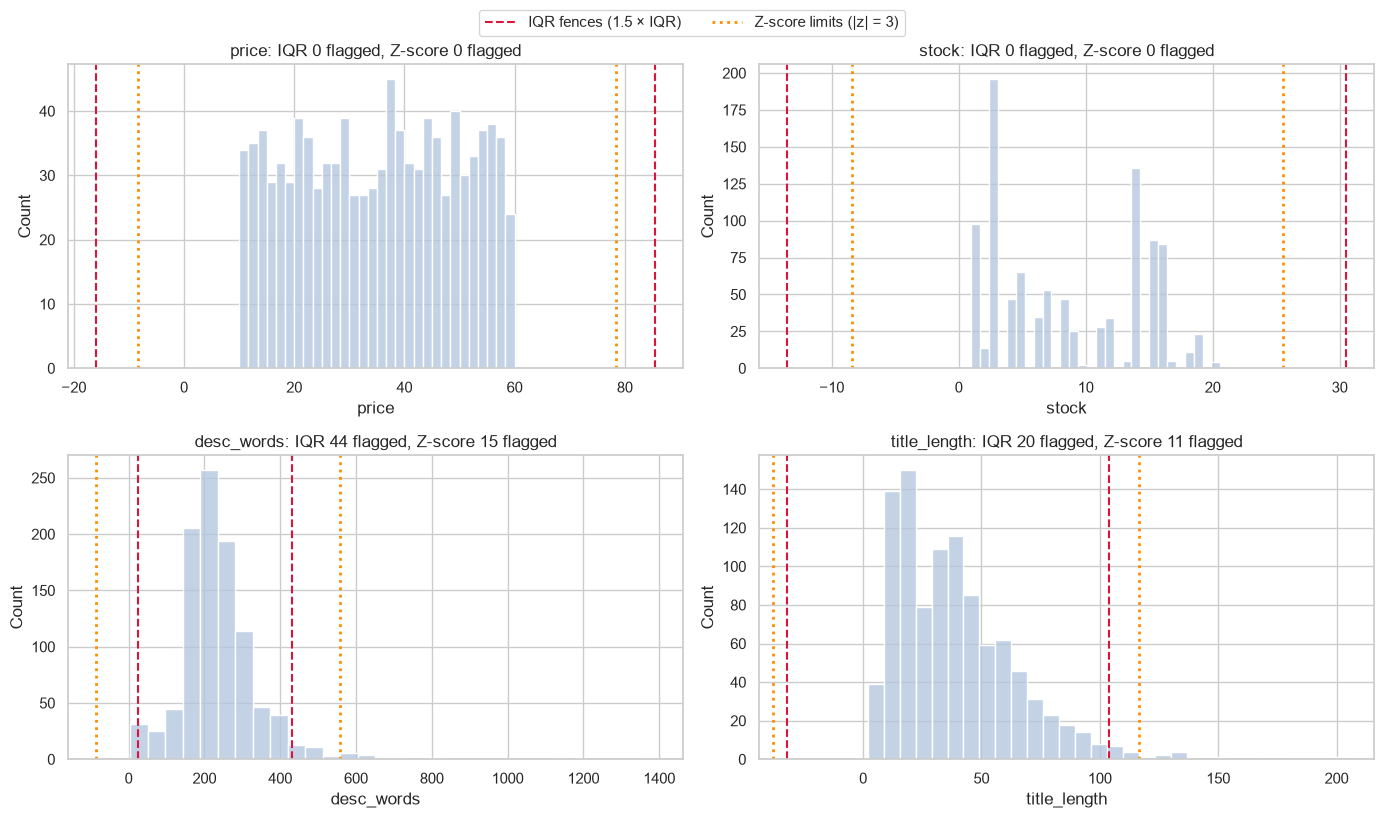

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], bins=30, ax=ax, color="lightsteelblue")
    low, high = iqr_bounds(df[col])
    z_low, z_high = mean[col] - Z_LIMIT * std[col], mean[col] + Z_LIMIT * std[col]
    for x in (low, high):
        ax.axvline(x, color="crimson", ls="--", lw=1.5)
    for x in (z_low, z_high):
        ax.axvline(x, color="darkorange", ls=":", lw=2)
    ax.set_title(f"{col}: IQR {iqr_flags[col].sum()} flagged, Z-score {z_flags[col].sum()} flagged")

handles = [plt.Line2D([], [], color="crimson", ls="--", label="IQR fences (1.5 × IQR)"),
           plt.Line2D([], [], color="darkorange", ls=":", lw=2, label="Z-score limits (|z| = 3)")]
fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
save(fig, "10_outlier_limits")
plt.show()

**What was done:** Plotted a histogram of each feature with the IQR fences (red dashed lines) and the Z-score limits (orange dotted lines).

**Why:** The visualization shows where each method places its limits relative to the actual data, which explains the counts in the comparison table.

**What the output shows / observations:**
- For **price** and **stock**, all limits lie outside the observed range, so no observations can be flagged. Price is bounded by the site between about £10 and £60.
- For **desc_words** and **title_length**, the upper IQR fence lies closer to the main body of the data than the upper Z-score limit, so the IQR method captures more of the right tail.
- For **desc_words**, only the IQR lower fence lies inside the data range, which is why only IQR flags the very short descriptions.

## 6. Investigation of the flagged observations
Every book flagged by at least one method is listed, and the longest titles and descriptions are inspected to determine whether the values are genuine or the result of a scraping error.

In [7]:
any_flag = iqr_flags.any(axis=1) | z_flags.any(axis=1)

def flagged_by(i):
    """Return the features and methods that flagged one book, e.g. 'desc_words (IQR + Z)'."""
    out = []
    for col in features:
        methods = [name for name, flags in (("IQR", iqr_flags), ("Z", z_flags)) if flags.at[i, col]]
        if methods:
            out.append(f"{col} ({' + '.join(methods)})")
    return ", ".join(out)

flagged = df.loc[any_flag, ["title", "category", "price", "stock", "desc_words", "title_length"]].copy()
flagged["flagged by"] = [flagged_by(i) for i in flagged.index]

print(len(flagged), "books flagged by at least one method (out of", len(df), ")")
flagged.sort_values(["desc_words", "title_length"], ascending=False).head(15)

62 books flagged by at least one method (out of 1000 )


,title,category,price,stock,desc_words,title_length,flagged by
512,Team of Rivals: The Political Genius of Abraha...,Add a comment,20.12,7,1389.0,55,desc_words (IQR + Z)
394,The Art of Startup Fundraising,Business,21.00,11,1123.0,30,desc_words (IQR + Z)
330,Buying In: The Secret Dialogue Between What We...,Nonfiction,37.80,14,802.0,65,desc_words (IQR + Z)
55,The Torch Is Passed: A Harding Family Story,Add a comment,19.09,16,721.0,43,desc_words (IQR + Z)
528,John Adams,Add a comment,57.43,7,677.0,10,desc_words (IQR + Z)
639,America's War for the Greater Middle East: A M...,History,51.22,5,639.0,61,desc_words (IQR + Z)
551,The Joy of Cooking,Add a comment,43.27,6,629.0,18,desc_words (IQR + Z)
736,The Name of God is Mercy,Nonfiction,37.25,3,625.0,24,desc_words (IQR + Z)
436,If I Gave You God's Phone Number....: Searchin...,Spirituality,20.91,9,618.0,75,desc_words (IQR + Z)
641,A Girl's Guide to Moving On (New Beginnings #2),Romance,31.30,5,599.0,47,desc_words (IQR + Z)


**What was done:** Listed every book flagged by at least one method, together with its title, category, price, stock, text lengths and the method(s) that flagged it, sorted from most to least extreme.

**Why:** The brief requires an investigation of whether flagged observations are valid values or possible data errors, using the context of the dataset.

**What the output shows / observations:**
- The flagged books have **ordinary prices and stock counts**. They are unusual only because of the length of their description or title, which agrees with the EDA scatter plots.

In [8]:
print("Longest titles:")
for _, row in df.nlargest(3, "title_length").iterrows():
    print(f"  {row['title_length']:>4} chars | {row['title']}")

print("\nLongest descriptions:")
for _, row in df.nlargest(3, "desc_words").iterrows():
    print(f"  {int(row['desc_words']):>4} words | {row['title']}")
    print(f"             {row['description'][:150]}...")

print("\nShortest descriptions:")
for _, row in df.nsmallest(3, "desc_words").iterrows():
    print(f"  {int(row['desc_words']):>4} words | {row['title']}")
    print(f"             {row['description'][:150]}")

Longest titles:
   204 chars | At The Existentialist Café: Freedom, Being, and apricot cocktails with: Jean-Paul Sartre, Simone de Beauvoir, Albert Camus, Martin Heidegger, Edmund Husserl, Karl Jaspers, Maurice Merleau-Ponty and others
   175 chars | Foolproof Preserving: A Guide to Small Batch Jams, Jellies, Pickles, Condiments, and More: A Foolproof Guide to Making Small Batch Jams, Jellies, Pickles, Condiments, and More
   163 chars | Political Suicide: Missteps, Peccadilloes, Bad Calls, Backroom Hijinx, Sordid Pasts, Rotten Breaks, and Just Plain Dumb Mistakes in the Annals of American Politics

Longest descriptions:
  1389 words | Team of Rivals: The Political Genius of Abraham Lincoln
             The life and times of Abraham Lincoln have been analyzed and dissected in countless books. Do we need another Lincoln biography? In Team of Rivals, es...
  1123 words | The Art of Startup Fundraising
             The Art of Startup Fundraising takes a fresh look at raising money for sta

**What was done:** Printed the three longest titles, the three longest descriptions and the three shortest descriptions in the dataset (descriptions shortened to their first 150 characters).

**Why:** Reading the actual text is the most direct way to verify whether an extreme length is a genuine property of the book or an error introduced by the scraper (for example, duplicated, broken or truncated HTML text).

**What the output shows / observations:**
- The longest titles include **subtitles or series names**, which is normal for real books.
- The longest descriptions are coherent, detailed product blurbs.
- The shortest descriptions are brief but still real text from the book's page, not empty or broken fields.
- **Conclusion:** the flagged observations are **genuine, correctly scraped values**, not data errors. Removing them would discard valid data.

## 7. Treatment decision

| Feature | Flagged | Decision | Justification |
|---|---|---|---|
| `price` | No | **Retain unchanged** | No outliers by either method; the range (£10 to £60) is fixed by the site. Price is also the regression target and must not be altered. |
| `stock` | No | **Retain unchanged** | No outliers by either method; 1 to 22 copies is a plausible range. |
| `desc_words` | Yes (44, both sides) | **Retain rows, cap values** | The values are genuine, so no rows are removed. Values outside the IQR fences are capped to limit their influence on linear models. |
| `title_length` | Yes (20, high side) | **Retain rows, cap values** | Same justification as `desc_words`. |
| `rating` | Not analysed | **Retain unchanged** | Bounded 1 to 5 scale; outlier detection is not applicable. |

**Why no rows are removed:** the flagged observations are real products with valid prices, ratings and stock. Removing them would reduce an already small dataset (1000 books) and make it less representative, without correcting any error.

**Why capping (winsorizing) is used:** capping keeps every book but replaces any value outside the fences with the nearest fence value. Linear regression is sensitive to extreme input values, which can have high leverage on the fitted line; capping limits this effect. Tree-based models are largely unaffected by such values.

In [9]:
TREAT = ["desc_words", "title_length"]

df_treated = df.copy()
for col in TREAT:
    low, high = iqr_bounds(df[col])
    df_treated[col] = df[col].clip(lower=low, upper=high)

summary = pd.DataFrame({
    "values capped": [(df[c].notna() & (df[c] != df_treated[c])).sum() for c in TREAT],
    "max before": df[TREAT].max().values,
    "max after": df_treated[TREAT].max().values,
    "skew before": df[TREAT].skew().values,
    "skew after": df_treated[TREAT].skew().values,
}, index=TREAT).round(2)

print("Rows before:", len(df), "| rows after:", len(df_treated), "(no books removed)")
summary

Rows before: 1000 | rows after: 1000 (no books removed)


,values capped,max before,max after,skew before,skew after
desc_words,44,1389.0,430.62,2.59,0.25
title_length,20,204.0,104.00,1.38,0.84


**What was done:** Capped `desc_words` and `title_length` at their IQR fences using `clip()` on a copy of the dataset (`df_treated`), and compared the number of capped values, the maximum and the skewness before and after.

**Why:** Applying the treatment to a copy keeps the original data available for comparison. Reporting the number of changed values and the change in skewness quantifies the effect of the treatment.

**What the output shows / observations:**
- The number of rows is unchanged: **no books were removed**.
- The number of capped values equals the number of IQR-flagged observations (44 for `desc_words`, 20 for `title_length`).
- The maximum of each treated feature now equals its upper IQR fence, and the very short descriptions are raised to the lower fence.
- The skewness of both features **decreases**, because the long right tail has been removed.

## 8. Before and after visualizations

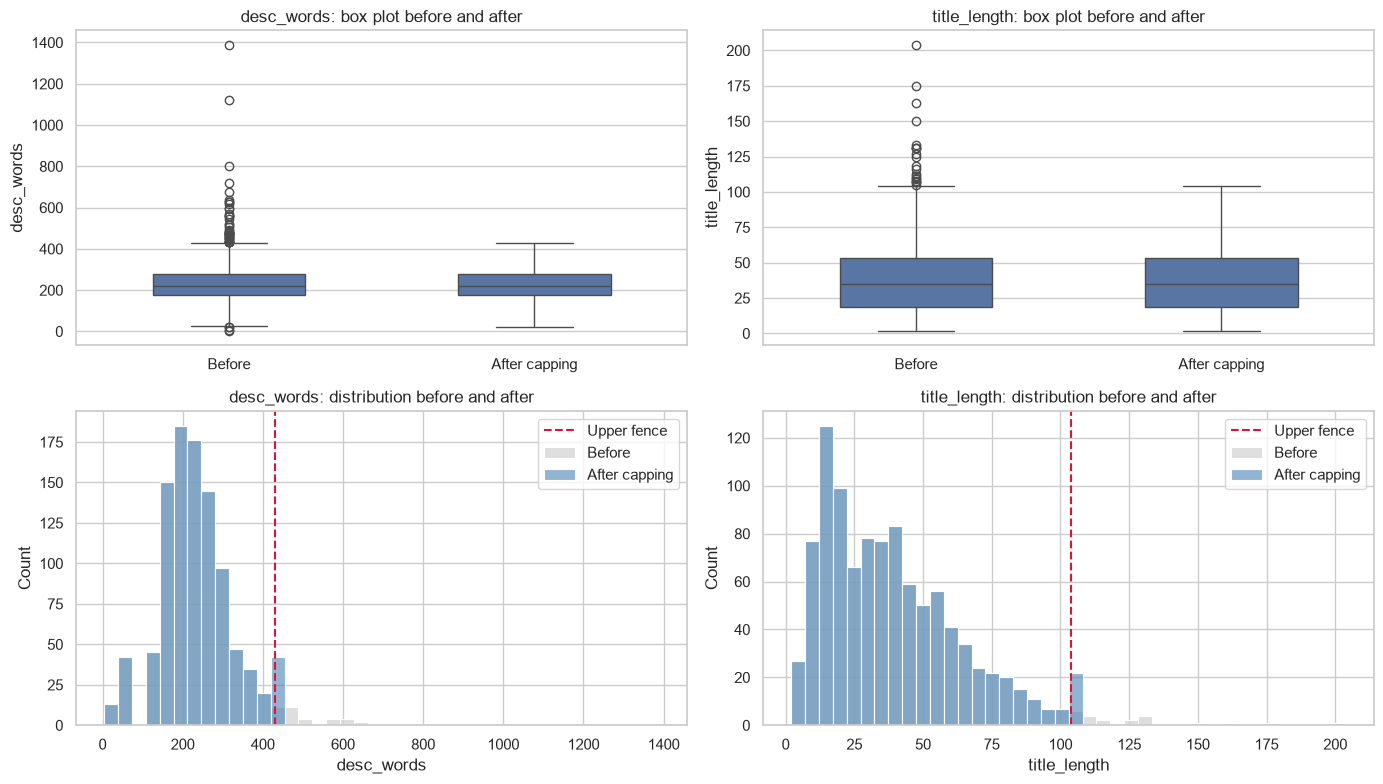

In [10]:
fig, axes = plt.subplots(2, len(TREAT), figsize=(14, 8))

for j, col in enumerate(TREAT):
    both = pd.DataFrame({"Before": df[col], "After capping": df_treated[col]}).melt(
        var_name="version", value_name=col)

    sns.boxplot(data=both, x="version", y=col, ax=axes[0, j], width=0.5)
    axes[0, j].set_title(f"{col}: box plot before and after")
    axes[0, j].set_xlabel("")

    edges = np.histogram_bin_edges(df[col].dropna(), bins=40)   # identical bins so the bar heights are directly comparable
    sns.histplot(df[col], bins=edges, ax=axes[1, j], color="lightgray", label="Before")
    sns.histplot(df_treated[col], bins=edges, ax=axes[1, j], color="steelblue", alpha=0.6, label="After capping")
    axes[1, j].axvline(iqr_bounds(df[col])[1], color="crimson", ls="--", label="Upper fence")
    axes[1, j].set_title(f"{col}: distribution before and after")
    axes[1, j].legend()

fig.tight_layout()
save(fig, "11_outliers_before_after")
plt.show()

**What was done:** Compared the treated features before and after capping using side-by-side box plots (top row) and overlaid histograms with identical bins (bottom row).

**Why:** The brief requires appropriate visualizations comparing the data before and after outlier treatment. Using the same bins for both histograms ensures the bar heights are directly comparable.

**What the output shows / observations:**
- **Box plots:** the points beyond the whiskers disappear after capping. The box (Q1, median, Q3) is unchanged, showing that the central part of the data is not affected.
- **Histograms:** the right tail is cut at the upper fence (red line), where the capped values form a small bar. All values between the fences are identical before and after.
- The treatment affects only the extreme observations, as intended.

## 9. Leakage-free treatment for modelling
The fences above were calculated from **all 1000 books**, which is appropriate for analysis. For modelling, however, Section 9 of the brief requires every preprocessing step to be **fitted on the training data only** and then applied to the test data without refitting. Fences calculated on the full dataset would leak information from the test set into training.

The capping is therefore implemented as a scikit-learn transformer, `IQRCapper`, so it can be included in the preprocessing pipeline.

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split

class IQRCapper(BaseEstimator, TransformerMixin):
    """Cap each column at Q1 - k*IQR and Q3 + k*IQR, using fences learned in fit() (training data only)."""

    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        self.lower_ = q1 - self.k * (q3 - q1)
        self.upper_ = q3 + self.k * (q3 - q1)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        X.columns = self.lower_.index       # align column labels for both DataFrame and NumPy input
        return X.clip(lower=self.lower_, upper=self.upper_, axis=1).to_numpy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.lower_.index.astype(str))

# Demonstration: 80/20 split, fences learned from the training set only
train, test = train_test_split(df[TREAT], test_size=0.2, random_state=42)
capper = IQRCapper().fit(train)

pd.DataFrame({
    "upper fence (all data)": [iqr_bounds(df[c])[1] for c in TREAT],
    "upper fence (training only)": capper.upper_.values,
    "test values capped": (test.notna().to_numpy() & (capper.transform(test) != test.to_numpy())).sum(axis=0),
}, index=TREAT).round(2)

,upper fence (all data),upper fence (training only),test values capped
desc_words,430.62,436.75,8
title_length,104.00,101.50,4


**What was done:** Defined the `IQRCapper` transformer. `fit()` learns the IQR fences from the data it receives, and `transform()` applies those fences to any data. As a demonstration, the two features were split 80/20, the capper was fitted on the training part only and then applied to the test part.

**Why:**
- Following the scikit-learn `fit` / `transform` interface allows the capper to be placed inside the Section 9 pipeline, guaranteeing that the fences come from the training data only.
- `get_feature_names_out` is implemented so the transformer also works inside a `ColumnTransformer`.

**What the output shows / observations:**
- The fences learned from the training data are very close to those from the full dataset, but are calculated **without using the test set**.
- The last column shows how many test values are capped using the training fences.
- **Note for Member 2:** in the final pipeline, `IQRCapper` should be applied to `desc_words` and `title_length` **after the imputer** (so no missing values remain) and **before the scaler**.

## 10. Summary
- **Features analysed:** `price`, `stock`, `desc_words` and `title_length`. `rating` was excluded because it is a bounded 1 to 5 scale.
- **Methods:** IQR (1.5 × IQR fences) and Z-score (|z| > 3).
- **Validity check:** no impossible values (non-positive prices, zero stock, empty titles), so there are no obvious data errors.
- **price** and **stock:** no outliers by either method.
- **Text-length features:** IQR flagged 44 descriptions (mostly long, plus a few very short ones) and 20 long titles. The **IQR method flagged more observations** than the Z-score method because the skewed tail inflates the standard deviation, and only IQR can detect the very short descriptions.
- **Investigation:** the flagged books are **genuine** (long subtitles, detailed or brief descriptions), not scraping errors.
- **Decision:** retain every book; cap `desc_words` and `title_length` at their IQR fences to limit their influence on linear models; leave `price`, `stock` and `rating` unchanged.
- **Modelling:** capping is performed with `IQRCapper`, fitted on the training data only, to avoid data leakage.